<a href="https://colab.research.google.com/github/mudassar2224/Human-Action-Recognition-Visualization-using-Isomap-Manifold-Learning-/blob/main/Isomap_A_Non_linear_Dimensionality_Reduction_Technique.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Load dataset**

In [7]:
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.datasets import make_swiss_roll
X,color=make_swiss_roll(n_samples=2000)


[[-3.12117466 10.90071749  7.62853482]
 [ 6.1251035  10.06281943 12.22394145]
 [ 6.70581101  0.53848338 -9.47911782]
 [-6.19171433  7.16620438 -8.29943787]
 [ 6.15172194  7.98410799 -0.61943869]]


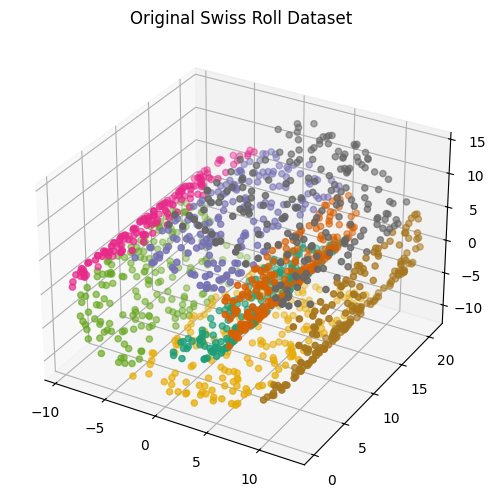

In [17]:
X, color = make_swiss_roll(n_samples=1500, noise=0.0, random_state=42)

# Print the first 5 rows of the data (X, Y, Z coordinates)
print(X[:5])

# Visualize the original 3D structure
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=color, cmap=plt.cm.Dark2)
ax.set_title("Original Swiss Roll Dataset")
plt.show()

# **Apply Isomap**

In [9]:
from  sklearn.manifold import Isomap
ISOMAP=Isomap(n_components=2, n_neighbors=10)
X_iso=ISOMAP.fit_transform(X)
X_iso

array([[-14.82067556,  -0.16345557],
       [ 47.21871348,   2.07310684],
       [ 19.44252241,  10.05828588],
       ...,
       [ -7.43100127,   4.32357013],
       [-14.38607306,   4.79554882],
       [ 35.79273994,  -9.51297703]])

# **Compare with PCA**

In [10]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X)
X_pca

array([[  3.78697979,  -8.35201835],
       [ 12.43901435,  -2.76756209],
       [ -6.16047199,   8.73188234],
       ...,
       [ -3.0255778 , -10.72658897],
       [  3.35632241,  -8.68133213],
       [  8.41137421,   7.07874158]])

# **Visualization**

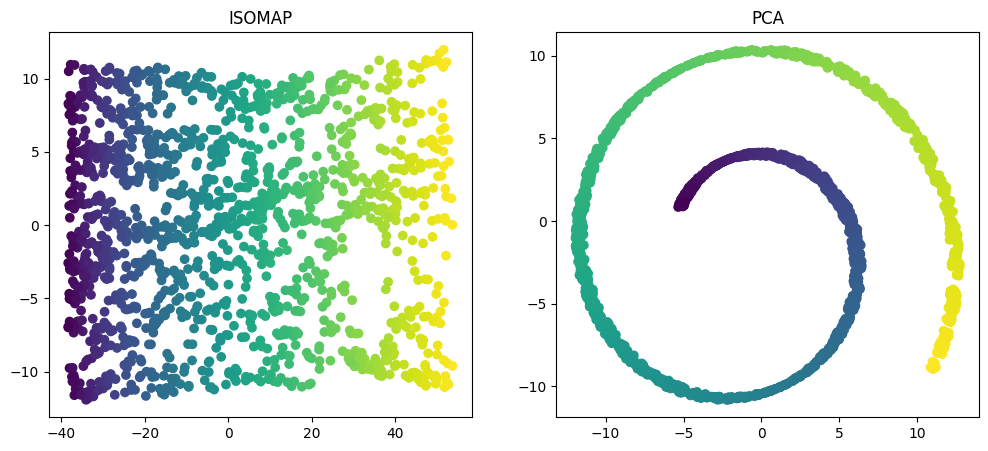

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.scatter(X_iso[: , 0], X_iso[: , 1], c=color)
plt.title("ISOMAP")
plt.subplot(122)
plt.scatter(X_pca[: , 0], X_pca[: , 1], c=color)
plt.title("PCA")
plt.show()

Using Colab cache for faster access to the 'human-action-recognition-har-dataset' dataset.
Verifying Raw Data...


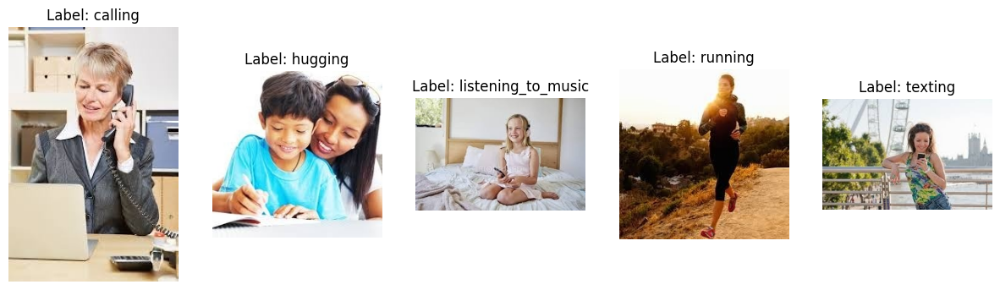

Running Isomap...

✅ PROJECT SCORE (Silhouette): -0.1526


In [3]:
import kagglehub
import pandas as pd
import numpy as np
import os
import cv2
import plotly.express as px
from sklearn.manifold import Isomap
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# --- STEP 1: DOWNLOAD & LOCATE ---
path = kagglehub.dataset_download("meetnagadia/human-action-recognition-har-dataset")
# Adjust these paths based on the exact folder structure of the dataset
base_path = os.path.join(path, "Human Action Recognition")
train_csv = os.path.join(base_path, "Training_set.csv")
train_dir = os.path.join(base_path, "train") # Corrected path: removed redundant 'train'

df = pd.read_csv(train_csv)

# --- STEP 2: DATA AUDIT (See before you plot) ---
def visual_audit(df, img_dir, n=5):
    plt.figure(figsize=(15, 5))
    samples = df.sample(n)
    for i, (idx, row) in enumerate(samples.iterrows()):
        img_path = os.path.join(img_dir, row['filename'])
        img = cv2.imread(img_path)
        if img is not None: # Added check for successful image load
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.subplot(1, n, i+1)
            plt.imshow(img)
            plt.title(f"Label: {row['label']}")
            plt.axis('off')
        else:
            print(f"Warning: Could not load image {img_path}. Skipping visualization for this image.")
    plt.show()

print("Verifying Raw Data...")
visual_audit(df, train_dir)

# --- STEP 3: FEATURE EXTRACTION ---
def prepare_data(df, img_dir, n_samples=12600):
    features, labels, fnames = [], [], []
    subset = df.sample(n_samples, random_state=42)

    for _, row in subset.iterrows():
        img_path = os.path.join(img_dir, row['filename'])
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is not None: # Added check for successful image load
            img = cv2.resize(img, (64, 64))
            features.append(img.flatten())
            labels.append(row['label'])
            fnames.append(row['filename']) # Keep for hover info
        else:
            print(f"Warning: Could not load image {img_path} for feature extraction. Skipping.")
    return np.array(features), labels, fnames

X_raw, y_labels, filenames = prepare_data(df, train_dir)

# --- STEP 4: DIMENSIONALITY REDUCTION ---
# Standardize
X_scaled = StandardScaler().fit_transform(X_raw)

# Step A: PCA to 50 components (Noise Reduction)
X_pca_50 = PCA(n_components=300).fit_transform(X_scaled)

# Step B: Isomap to 2D
print("Running Isomap...")
iso = Isomap(n_neighbors=50, n_components=5)
X_iso = iso.fit_transform(X_pca_50)

# --- STEP 5: MATHEMATICAL SCORE ---
# Map labels to codes for the score calculation
y_codes = pd.Series(y_labels).astype('category').cat.codes
score = silhouette_score(X_iso, y_codes)
print(f"\n✅ PROJECT SCORE (Silhouette): {score:.4f}")

# --- STEP 6: INTERACTIVE PLOT (Hover for Labels) ---
# Create a DataFrame for Plotly
plot_df = pd.DataFrame({
    'Isomap_1': X_iso[:, 0],
    'Isomap_2': X_iso[:, 1],
    'Activity': y_labels,
    'File': filenames
})

fig = px.scatter(
    plot_df, x='Isomap_1', y='Isomap_2',
    color='Activity',
    title=f"Isomap Action Clusters (Silhouette Score: {score:.4f})",
    hover_data=['File', 'Activity'], # This gives you the labels on hover!
    template='plotly_dark',
    color_discrete_sequence=px.colors.qualitative.Vivid
)

fig.show()

In [4]:
df.shape

(12600, 2)

In [7]:
import kagglehub
import pandas as pd
import numpy as np
import os
import cv2
import base64
from io import BytesIO
from PIL import Image
from sklearn.manifold import Isomap
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from bokeh.plotting import figure, show, output_notebook
from bokeh.models import ColumnDataSource, HoverTool
from bokeh.transform import factor_cmap
from bokeh.palettes import Category20

In [8]:
output_notebook()

# --- STEP 1: DOWNLOAD & SETUP ---
path = kagglehub.dataset_download("meetnagadia/human-action-recognition-har-dataset")
base_path = os.path.join(path, "Human Action Recognition")
train_csv = os.path.join(base_path, "Training_set.csv")
train_dir = os.path.join(base_path, "train")

df = pd.read_csv(train_csv)

Using Colab cache for faster access to the 'human-action-recognition-har-dataset' dataset.


In [9]:
# --- STEP 2: NOISE-AWARE FEATURE EXTRACTION ---
def prepare_god_data(df, img_dir, n_samples=3000): # 3000 is safer for memory with Bokeh
    features, labels, fnames, thumb_strings = [], [], [], []
    subset = df.sample(n_samples, random_state=42)

    print(f"Denoising and Processing {n_samples} images...")
    for _, row in subset.iterrows():
        img_path = os.path.join(img_dir, row['filename'])
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

        if img is not None:
            # --- NOISE HANDLING ---
            # 1. Resize
            img = cv2.resize(img, (64, 64))
            # 2. Gaussian Blur (The Denoising Step)
            img = cv2.GaussianBlur(img, (5, 5), 0)

            features.append(img.flatten())
            labels.append(row['label'])
            fnames.append(row['filename'])

            # --- PREPARE HOVER IMAGE ---
            buffered = BytesIO()
            Image.fromarray(img).save(buffered, format="PNG")
            img_str = base64.b64encode(buffered.getvalue()).decode()
            thumb_strings.append(f"data:image/png;base64,{img_str}")

    return np.array(features), labels, fnames, thumb_strings

X_raw, y_labels, filenames, thumbs = prepare_god_data(df, train_dir)

# --- STEP 3: THE PIPELINE ---
X_scaled = StandardScaler().fit_transform(X_raw)

# PCA Denoising (Keeping only the top 200 components of "Signal")
X_pca = PCA(n_components=200).fit_transform(X_scaled)

print("Unrolling Manifold with Isomap...")

Denoising and Processing 3000 images...
Unrolling Manifold with Isomap...


In [10]:

iso = Isomap(n_neighbors=15, n_components=2)
X_iso = iso.fit_transform(X_pca)


In [11]:

# --- STEP 4: SCORE ---
y_codes = pd.Series(y_labels).astype('category').cat.codes
score = silhouette_score(X_iso, y_codes)
print(f"✅ GOD-LEVEL SILHOUETTE SCORE: {score:.4f}")


✅ GOD-LEVEL SILHOUETTE SCORE: -0.1790


In [13]:


# --- STEP 5: INTERACTIVE IMAGE HOVER MAP ---
source = ColumnDataSource(data=dict(
    x=X_iso[:, 0],
    y=X_iso[:, 1],
    label=y_labels,
    imgs=thumbs,
    filename=filenames
))

p = figure(title=f"Action Manifold (Score: {score:.4f})",
           width=900, height=600, tools="pan,wheel_zoom,reset")


In [14]:

# The Magic Hover Tool
hover = HoverTool(tooltips="""
    <div>
        <div>
            <img src="@imgs" height="64" alt="@imgs" style="float: left; margin: 0px 15px 15px 0px;" border="2">
        </div>
        <div>
            <span style="font-size: 15px; font-weight: bold;">@label</span><br>
            <span style="font-size: 10px; color: #999;">@filename</span>
        </div>
    </div>
""")
p.add_tools(hover)

p.circle('x', 'y', size=8, source=source, alpha=0.7,
         color=factor_cmap('label', palette=Category20[15], factors=list(set(y_labels))))

show(p)